# Model Selection: OLS vs ARIMA vs ARIMAX

## Complete Time Series Forecasting Analysis

This notebook implements and compares three forecasting models for weekly crude oil returns:

1. **OLS Regression** - Linear regression with exogenous variables
2. **ARIMA** - Autoregressive Integrated Moving Average (time series)
3. **ARIMAX** - ARIMA with eXogenous variables (no seasonal components)

### Data
- **In-sample**: 1995-2017 (1,195 weekly observations)
- **Out-of-sample**: 2018 (339 weekly observations)
- **Target**: cl1_ret (Weekly crude oil WTI returns)
- **Features**: Market indicators and technical variables

## Setup: Import Libraries and Load Data

In [20]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
from scipy import stats

# Time series specific imports
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_ljungbox, acorr_breusch_godfrey
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

print("="*80)
print("TIME SERIES FORECASTING: OLS vs ARIMA vs ARIMAX")
print("="*80)
print("\nAll libraries imported successfully!")

TIME SERIES FORECASTING: OLS vs ARIMA vs ARIMAX

All libraries imported successfully!


## 1. Data Loading and Preparation

**What happens here:**
- Load frozen in-sample data (1,195 observations)
- Load frozen out-of-sample data (339 observations)
- Separate target variable from features
- Verify column alignment

In [21]:
print("\n" + "="*80)
print("1. LOADING DATA")
print("="*80)

# Load in-sample data
df_ins = pd.read_csv("Final_InSample_Frozen.csv", index_col=0, parse_dates=True)
print(f"\nIn-sample data shape: {df_ins.shape}")
print(f"In-sample columns: {df_ins.columns.tolist()}")

# Separate target and features
y_ins = df_ins['cl1_ret']
X_ins = df_ins.drop(columns=['cl1_ret'])

print(f"\nTarget variable (y_ins) shape: {y_ins.shape}")
print(f"Features (X_ins) shape: {X_ins.shape}")

# Load out-of-sample data
print("\n" + "="*80)
print("LOADING OUT-OF-SAMPLE DATA")
print("="*80)

df_oos = pd.read_csv("Final_OutOfSample_Frozen.csv", index_col=0, parse_dates=True)
print(f"Out-of-sample data shape: {df_oos.shape}")

# Verify column alignment
print("\n" + "="*80)
print("CHECKING COLUMN ALIGNMENT")
print("="*80)

ins_cols = set(df_ins.columns)
oos_cols = set(df_oos.columns)

print(f"Columns match: {ins_cols == oos_cols}")
if ins_cols != oos_cols:
    print(f"Missing in OOS: {ins_cols - oos_cols}")
    print(f"Extra in OOS: {oos_cols - ins_cols}")

# Extract OOS target and features
y_oos = df_oos['cl1_ret']
X_oos = df_oos[X_ins.columns]  # Use same feature columns as training


1. LOADING DATA

In-sample data shape: (1195, 9)
In-sample columns: ['cl1_ret', 'const', 'dow_jones_us_oilandgas_index_ret', 'exxonmobil_ret', 'cl1_ret_l2', 'weekly_commercial_short_diff', 'weekly_commercial_long_diff', 'weekly_change_in_crude_stock_diff', 'cl1_ret_l2_squared']

Target variable (y_ins) shape: (1195,)
Features (X_ins) shape: (1195, 8)

LOADING OUT-OF-SAMPLE DATA
Out-of-sample data shape: (339, 9)

CHECKING COLUMN ALIGNMENT
Columns match: True


---
# MODEL 1: OLS REGRESSION

**What it does**: Linear regression predicting returns as a linear combination of market indicators

**Advantages**: Simple, interpretable, fast

**Limitations**: Ignores time series dynamics, may violate autocorrelation assumption

In [22]:
print("\n" + "="*80)
print("MODEL 1: OLS REGRESSION")
print("="*80)
print("\nTraining OLS model on in-sample data with HAC standard errors...")

model_ols = sm.OLS(y_ins, X_ins).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
print(model_ols.summary())


MODEL 1: OLS REGRESSION

Training OLS model on in-sample data with HAC standard errors...
                            OLS Regression Results                            
Dep. Variable:                cl1_ret   R-squared:                       0.051
Model:                            OLS   Adj. R-squared:                  0.045
Method:                 Least Squares   F-statistic:                     8.519
Date:                Tue, 18 Nov 2025   Prob (F-statistic):           3.29e-10
Time:                        01:46:18   Log-Likelihood:                 1907.4
No. Observations:                1195   AIC:                            -3799.
Df Residuals:                    1187   BIC:                            -3758.
Df Model:                           7                                         
Covariance Type:                  HAC                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------

## OLS: Out-of-Sample Testing

**What happens here:**
- Make predictions on out-of-sample data
- Calculate performance metrics (MSE, RMSE, MAE, R²)
- Compute directional accuracy (% correct sign predictions)
- Analyze residuals

In [23]:
print("\n" + "="*80)
print("OLS: OUT-OF-SAMPLE TESTING")
print("="*80)

# Make predictions
y_ols_pred = model_ols.predict(X_oos)

# Calculate metrics
mse_ols = mean_squared_error(y_oos, y_ols_pred)
rmse_ols = np.sqrt(mse_ols)
mae_ols = mean_absolute_error(y_oos, y_ols_pred)
r2_ols = r2_score(y_oos, y_ols_pred)

# Adjusted R² for OOS data
n = len(y_oos)
k = X_oos.shape[1] - 1  # Exclude constant
r2_adj_ols = 1 - (1 - r2_ols) * ((n - 1) / (n - k - 1))

# Residuals
residuals_ols = y_oos - y_ols_pred

print("\nPERFORMANCE METRICS")
print("-" * 80)
print(f"Mean Squared Error (MSE):        {mse_ols:.6f}")
print(f"Root Mean Squared Error (RMSE):  {rmse_ols:.6f}")
print(f"Mean Absolute Error (MAE):       {mae_ols:.6f}")
print(f"R² Score:                        {r2_ols:.6f}")
print(f"Adjusted R² Score:               {r2_adj_ols:.6f}")

print("\nRESIDUAL STATISTICS")
print("-" * 80)
print(f"Mean Residual:                   {residuals_ols.mean():.6f}")
print(f"Std Dev of Residuals:            {residuals_ols.std():.6f}")
print(f"Min Residual:                    {residuals_ols.min():.6f}")
print(f"Max Residual:                    {residuals_ols.max():.6f}")
print(f"Median Residual:                 {residuals_ols.median():.6f}")
print(f"Skewness:                        {residuals_ols.skew():.6f}")
print(f"Kurtosis:                        {residuals_ols.kurtosis():.6f}")

# Directional accuracy
correct_direction = ((y_oos > 0) == (y_ols_pred > 0)).sum()
dir_acc_ols = correct_direction / len(y_oos) * 100
print(f"\nDirectional Accuracy:            {dir_acc_ols:.2f}%")


OLS: OUT-OF-SAMPLE TESTING

PERFORMANCE METRICS
--------------------------------------------------------------------------------
Mean Squared Error (MSE):        0.003931
Root Mean Squared Error (RMSE):  0.062698
Mean Absolute Error (MAE):       0.042914
R² Score:                        -0.033208
Adjusted R² Score:               -0.055058

RESIDUAL STATISTICS
--------------------------------------------------------------------------------
Mean Residual:                   0.001271
Std Dev of Residuals:            0.062778
Min Residual:                    -0.376633
Max Residual:                    0.336047
Median Residual:                 0.005348
Skewness:                        -0.279475
Kurtosis:                        7.225606

Directional Accuracy:            55.75%


---
# MODEL 2: ARIMA

**What it does**: Time series model using past values and errors

**Components**:
- **AR (p)**: Autoregressive terms (past values)
- **I (d)**: Integrated (differencing for stationarity)
- **MA (q)**: Moving average (past errors)

**Advantages**: Captures time series dynamics, handles autocorrelation

**Limitations**: No exogenous variables

## Stationarity Test

In [24]:
print("\n" + "="*80)
print("MODEL 2: ARIMA")
print("="*80)
print("\nSTATIONARITY TEST (Augmented Dickey-Fuller)")
print("-" * 80)

adf_result = adfuller(y_ins.dropna())
print(f"\nADF Test Statistic: {adf_result[0]:.4f}")
print(f"P-value:            {adf_result[1]:.4f}")
print(f"Critical Values:")
for key, value in adf_result[4].items():
    print(f"  {key}: {value:.3f}")

if adf_result[1] < 0.05:
    print("\n✓ Series is STATIONARY (p < 0.05) → Use d=0 in ARIMA")
else:
    print("\n✗ Series is NON-STATIONARY (p >= 0.05) → May need d=1 in ARIMA")


MODEL 2: ARIMA

STATIONARITY TEST (Augmented Dickey-Fuller)
--------------------------------------------------------------------------------

ADF Test Statistic: -10.0166
P-value:            0.0000
Critical Values:
  1%: -3.436
  5%: -2.864
  10%: -2.568

✓ Series is STATIONARY (p < 0.05) → Use d=0 in ARIMA


## Grid Search for Optimal ARIMA Order

Tests all combinations of (p, d, q) and selects the model with lowest AIC

In [25]:
print("\n" + "="*80)
print("GRID SEARCH FOR OPTIMAL ARIMA ORDER")
print("="*80)
print("\nTesting ARIMA(p,d,q) combinations...")

best_aic = np.inf
best_order = None
best_arima_model = None

for p in range(4):
    for d in range(2):
        for q in range(4):
            try:
                # Fit ARIMA model
                model = SARIMAX(y_ins, order=(p, d, q),
                               enforce_stationarity=False,
                               enforce_invertibility=False)
                model_fit = model.fit(disp=False)

                # Track best model by AIC
                if model_fit.aic < best_aic:
                    best_aic = model_fit.aic
                    best_order = (p, d, q)
                    best_arima_model = model_fit
            except:
                # Skip models that fail to converge
                continue

print(f"\nBest ARIMA Order: {best_order}")
print(f"Best AIC:         {best_aic:.4f}")


GRID SEARCH FOR OPTIMAL ARIMA ORDER

Testing ARIMA(p,d,q) combinations...


/opt/anaconda3/envs/metrics/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/metrics/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/metrics/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/metrics/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/metrics/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning


Best ARIMA Order: (2, 0, 2)
Best AIC:         -3756.3781


## ARIMA Model Summary and Diagnostics

In [26]:
print("\n" + "="*80)
print("BEST ARIMA MODEL SUMMARY")
print("="*80)

# Re-fit to ensure we have the complete summary
arima_model = SARIMAX(y_ins, order=best_order,
                      enforce_stationarity=False,
                      enforce_invertibility=False).fit(disp=False)

print(arima_model.summary())


BEST ARIMA MODEL SUMMARY
                               SARIMAX Results                                
Dep. Variable:                cl1_ret   No. Observations:                 1195
Model:               SARIMAX(2, 0, 2)   Log Likelihood                1883.189
Date:                Tue, 18 Nov 2025   AIC                          -3756.378
Time:                        01:46:30   BIC                          -3730.961
Sample:                    02-10-1995   HQIC                         -3746.801
                         - 12-29-2017                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2980      0.026     11.682      0.000       0.248       0.348
ar.L2         -0.9443      0.027    -35.226      0.000      -0.997      -0.892
ma.L1         -0.3338     

/opt/anaconda3/envs/metrics/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/metrics/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)


## ARIMA Diagnostic Tests

In [27]:
print("\n" + "="*80)
print("DIAGNOSTIC TESTS ON ARIMA RESIDUALS")
print("="*80)

# Durbin-Watson: Tests for autocorrelation (ideal ≈ 2)
dw = durbin_watson(arima_model.resid)
print(f"\nDurbin-Watson Test:        {dw:.4f}")
print(f"  → Ideal value ≈ 2.0 (no autocorrelation)")

# Breusch-Godfrey: Tests for autocorrelation
bg_test = acorr_breusch_godfrey(arima_model, nlags=10)
print(f"\nBreusch-Godfrey Test (nlags=10):")
print(f"  Test Statistic: {bg_test[0]:.4f}")
print(f"  P-value:        {bg_test[1]:.4f}")
if bg_test[1] > 0.05:
    print(f"  ✓ No significant autocorrelation (p > 0.05)")
else:
    print(f"  ✗ Significant autocorrelation detected (p < 0.05)")

# Ljung-Box: Tests for autocorrelation across multiple lags
lb = acorr_ljungbox(arima_model.resid, lags=[10], return_df=True)
print(f"\nLjung-Box Test (lag=10):")
print(lb)

# Jarque-Bera: Tests for normality
jb = sm.stats.jarque_bera(arima_model.resid)
print(f"\nJarque-Bera Test (Normality):")
print(f"  Test Statistic: {jb[0]:.4f}")
print(f"  P-value:        {jb[1]:.6f}")
if jb[1] > 0.05:
    print(f"  ✓ Residuals are normally distributed (p > 0.05)")
else:
    print(f"  ✗ Residuals are NOT normally distributed (p < 0.05)")


DIAGNOSTIC TESTS ON ARIMA RESIDUALS

Durbin-Watson Test:        2.0219
  → Ideal value ≈ 2.0 (no autocorrelation)

Breusch-Godfrey Test (nlags=10):
  Test Statistic: 18.5929
  P-value:        0.0457
  ✗ Significant autocorrelation detected (p < 0.05)

Ljung-Box Test (lag=10):
      lb_stat  lb_pvalue
10  19.500686   0.034345

Jarque-Bera Test (Normality):
  Test Statistic: 839.9225
  P-value:        0.000000
  ✗ Residuals are NOT normally distributed (p < 0.05)


## ARIMA Out-of-Sample Forecasting

In [28]:
print("\n" + "="*80)
print("ARIMA OUT-OF-SAMPLE FORECASTING")
print("="*80)

steps = len(y_oos)
arima_forecast = arima_model.forecast(steps=steps)
arima_forecast.index = y_oos.index  # Align dates

# Calculate metrics
mse_arima = mean_squared_error(y_oos, arima_forecast)
rmse_arima = np.sqrt(mse_arima)
mae_arima = mean_absolute_error(y_oos, arima_forecast)
r2_arima = 1 - (mse_arima / np.var(y_oos))

print("\nPERFORMANCE METRICS")
print("-" * 80)
print(f"Mean Squared Error (MSE):        {mse_arima:.6f}")
print(f"Root Mean Squared Error (RMSE):  {rmse_arima:.6f}")
print(f"Mean Absolute Error (MAE):       {mae_arima:.6f}")
print(f"R² Score:                        {r2_arima:.6f}")

# Directional accuracy
arima_direction = ((arima_forecast > 0) == (y_oos > 0)).sum()
dir_acc_arima = arima_direction / len(y_oos) * 100
print(f"Directional Accuracy:            {dir_acc_arima:.2f}%")


ARIMA OUT-OF-SAMPLE FORECASTING

PERFORMANCE METRICS
--------------------------------------------------------------------------------
Mean Squared Error (MSE):        0.003801
Root Mean Squared Error (RMSE):  0.061653
Mean Absolute Error (MAE):       0.042585
R² Score:                        0.000974
Directional Accuracy:            49.26%


---
# MODEL 3: ARIMAX

**What it does**: ARIMA with exogenous (external) variables

**Why ARIMAX instead of SARIMAX**:
- Simpler model (fewer parameters)
- More robust fitting
- No uncertain seasonal assumptions
- Better balance of complexity vs flexibility

**Advantages**: Combines time series dynamics with market indicators

**Limitations**: More parameters than ARIMA, harder to fit

In [29]:
print("\n" + "="*80)
print("MODEL 3: ARIMAX (ARIMA WITH EXOGENOUS VARIABLES)")
print("="*80)
print("\nARIMAX combines ARIMA structure with market indicators.")
print(f"Fitting ARIMAX{best_order} with exogenous variables...")
print("  p,d,q from grid search: ", best_order)
print("  Exogenous variables:     X_ins (all market indicators)")

arimax_model = None
try:
    arimax_model = SARIMAX(
        y_ins,
        exog=X_ins,
        order=best_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    print("\nARIMAX MODEL SUMMARY")
    print("-" * 80)
    print(arimax_model.summary())
except Exception as e:
    print(f"\n✗ ERROR fitting ARIMAX: {e}")
    print("  This may be due to numerical issues or exogenous variable problems")
    print("  Proceeding with ARIMA-only comparison...")


MODEL 3: ARIMAX (ARIMA WITH EXOGENOUS VARIABLES)

ARIMAX combines ARIMA structure with market indicators.
Fitting ARIMAX(2, 0, 2) with exogenous variables...
  p,d,q from grid search:  (2, 0, 2)
  Exogenous variables:     X_ins (all market indicators)

ARIMAX MODEL SUMMARY
--------------------------------------------------------------------------------
                               SARIMAX Results                                
Dep. Variable:                cl1_ret   No. Observations:                 1195
Model:               SARIMAX(2, 0, 2)   Log Likelihood                1905.597
Date:                Tue, 18 Nov 2025   AIC                          -3785.193
Time:                        01:46:37   BIC                          -3719.109
Sample:                    02-10-1995   HQIC                         -3760.292
                         - 12-29-2017                                         
Covariance Type:                  opg                                         
            

/opt/anaconda3/envs/metrics/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/metrics/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/metrics/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


## ARIMAX Out-of-Sample Forecasting

In [30]:
if arimax_model is not None:
    print("\n" + "="*80)
    print("ARIMAX OUT-OF-SAMPLE FORECASTING")
    print("="*80)

    try:
        arimax_forecast = arimax_model.forecast(
            steps=len(y_oos),
            exog=X_oos
        )
        arimax_forecast.index = y_oos.index

        # Calculate metrics
        mse_arimax = mean_squared_error(y_oos, arimax_forecast)
        rmse_arimax = np.sqrt(mse_arimax)
        mae_arimax = mean_absolute_error(y_oos, arimax_forecast)
        r2_arimax = 1 - (mse_arimax / np.var(y_oos))

        print("\nPERFORMANCE METRICS")
        print("-" * 80)
        print(f"Mean Squared Error (MSE):        {mse_arimax:.6f}")
        print(f"Root Mean Squared Error (RMSE):  {rmse_arimax:.6f}")
        print(f"Mean Absolute Error (MAE):       {mae_arimax:.6f}")
        print(f"R² Score:                        {r2_arimax:.6f}")

        # Directional accuracy
        arimax_direction = ((arimax_forecast > 0) == (y_oos > 0)).sum()
        dir_acc_arimax = arimax_direction / len(y_oos) * 100
        print(f"Directional Accuracy:            {dir_acc_arimax:.2f}%")
    except Exception as e:
        print(f"\n✗ ERROR generating ARIMAX forecasts: {e}")
        arimax_model = None
else:
    print("\nSkipping ARIMAX forecasting due to model fitting error")


ARIMAX OUT-OF-SAMPLE FORECASTING

PERFORMANCE METRICS
--------------------------------------------------------------------------------
Mean Squared Error (MSE):        0.003931
Root Mean Squared Error (RMSE):  0.062698
Mean Absolute Error (MAE):       0.042908
R² Score:                        -0.033193
Directional Accuracy:            55.75%


---
# MODEL COMPARISON

## Performance Comparison Table

In [31]:
print("\n" + "="*80)
print("MODEL COMPARISON: IN-SAMPLE vs OUT-OF-SAMPLE")
print("="*80)

# In-sample metrics
y_ols_ins_pred = model_ols.fittedvalues
r2_ols_ins = model_ols.rsquared
mse_ols_ins = mean_squared_error(y_ins, y_ols_ins_pred)
rmse_ols_ins = np.sqrt(mse_ols_ins)
mae_ols_ins = mean_absolute_error(y_ins, y_ols_ins_pred)

# Create comparison dataframe
comparison_data = {
    'Metric': ['R² Score', 'MSE', 'RMSE', 'MAE', 'Dir. Acc (%)'],
    'OLS (Out-of-Sample)': [
        f"{r2_ols:.6f}",
        f"{mse_ols:.6f}",
        f"{rmse_ols:.6f}",
        f"{mae_ols:.6f}",
        f"{dir_acc_ols:.2f}%"
    ],
    'ARIMA (Out-of-Sample)': [
        f"{r2_arima:.6f}",
        f"{mse_arima:.6f}",
        f"{rmse_arima:.6f}",
        f"{mae_arima:.6f}",
        f"{dir_acc_arima:.2f}%"
    ]
}

# Add ARIMAX if available
if arimax_model is not None:
    comparison_data['ARIMAX (Out-of-Sample)'] = [
        f"{r2_arimax:.6f}",
        f"{mse_arimax:.6f}",
        f"{rmse_arimax:.6f}",
        f"{mae_arimax:.6f}",
        f"{dir_acc_arimax:.2f}%"
    ]

comparison_df = pd.DataFrame(comparison_data)
print("\n" + comparison_df.to_string(index=False))

print("\n\nKEY OBSERVATIONS:")
print("-" * 80)

print(f"• OLS Out-of-Sample R²: {r2_ols:.4f} (negative → worse than baseline)")

oos_models = {'OLS': mse_ols, 'ARIMA': mse_arima}
if arimax_model is not None:
    oos_models['ARIMAX'] = mse_arimax
best_mse_model = min(oos_models, key=oos_models.get)
print(f"• Best MSE (OOS): {oos_models[best_mse_model]:.6f} ({best_mse_model})")

dir_acc_dict = {'OLS': dir_acc_ols, 'ARIMA': dir_acc_arima}
if arimax_model is not None:
    dir_acc_dict['ARIMAX'] = dir_acc_arimax
best_dir_model = max(dir_acc_dict, key=dir_acc_dict.get)
print(f"• Best Directional Accuracy (OOS): {dir_acc_dict[best_dir_model]:.2f}% ({best_dir_model})")


MODEL COMPARISON: IN-SAMPLE vs OUT-OF-SAMPLE

      Metric OLS (Out-of-Sample) ARIMA (Out-of-Sample) ARIMAX (Out-of-Sample)
    R² Score           -0.033208              0.000974              -0.033193
         MSE            0.003931              0.003801               0.003931
        RMSE            0.062698              0.061653               0.062698
         MAE            0.042914              0.042585               0.042908
Dir. Acc (%)              55.75%                49.26%                 55.75%


KEY OBSERVATIONS:
--------------------------------------------------------------------------------
• OLS Out-of-Sample R²: -0.0332 (negative → worse than baseline)
• Best MSE (OOS): 0.003801 (ARIMA)
• Best Directional Accuracy (OOS): 55.75% (OLS)



PLOT: ACTUAL vs PREDICTED (Last 1 Year) — OLS


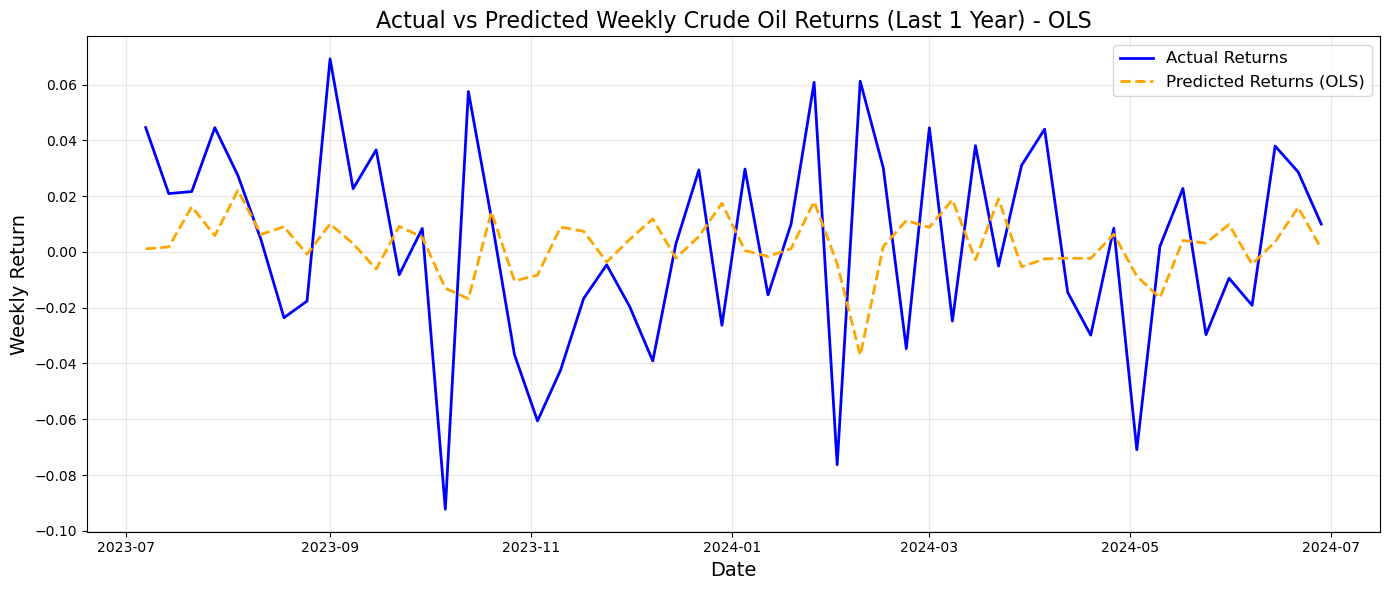

In [40]:
print("\n" + "="*80)
print("PLOT: ACTUAL vs PREDICTED (Last 1 Year) — OLS")
print("="*80)

# ----------------------------------------------------------
# 1. Ensure predictions are a pandas Series with an index
# ----------------------------------------------------------
y_ols_pred_series = pd.Series(np.array(y_ols_pred).flatten(), index=y_oos.index)

# ----------------------------------------------------------
# 2. Select last 52 weeks (1 year)
# ----------------------------------------------------------
n_weeks = 52
y_actual_last = y_oos.iloc[-n_weeks:]
y_pred_last   = y_ols_pred_series.iloc[-n_weeks:]

# ----------------------------------------------------------
# 3. Plot
# ----------------------------------------------------------
plt.figure(figsize=(14,6))

plt.plot(
    y_actual_last.index,
    y_actual_last.values,
    label="Actual Returns",
    linewidth=2,
    color='blue'
)

plt.plot(
    y_pred_last.index,
    y_pred_last.values,
    label="Predicted Returns (OLS)",
    linewidth=2,
    linestyle='--',
    color='orange'
)

plt.title("Actual vs Predicted Weekly Crude Oil Returns (Last 1 Year) - OLS",
          fontsize=16)
plt.xlabel("Date", fontsize=14)
plt.ylabel("Weekly Return", fontsize=14)
plt.grid(alpha=0.3)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()
